# Problem 2 · Crowdedness-aware journey planner — data exploration

**Transport Stack Hackathon 2026, Phase 1.** Dataset: Delhi bus e-ticketing, 1–31 October 2026 (`October-Delhi.csv`, ~2.56 M tickets).

**The problem in one paragraph.** Journey planners rank trips only by time and transfers, but how crowded the bus is matters just as much.
Using ~4–5 weeks of ticket records, estimate **how many people are on board, by route, direction, stretch between stops and time of day**,
turn that into a level a commuter understands (*seats available / standing room / crowded*), and show it next to each option in a
journey planner built on static GTFS, so the user can trade a faster trip for a more comfortable one.
Judged on **how well the crowding estimate is grounded in the data** and **how clearly it is shown**. The crowding model is the main
contribution — "a simple planner with a sound crowding model beats a polished planner with a weak one".

**Phase 1 deliverables:** a rerunnable pipeline (tickets → crowding), queryable/mappable crowding outputs, a planner/demo screen,
a short technical note (method, assumptions, where estimates are least reliable), and checks against known patterns
(AM/PM peaks, busy corridors, weekday vs weekend).

This notebook answers: **what is in the data, how clean is it, and what can (and can't) be built from it.**

In [1]:
import time
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.colors import LinearSegmentedColormap

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
RAW = ROOT / 'data' / 'raw' / 'October-Delhi.csv'
PROC = ROOT / 'data' / 'processed'
PROC.mkdir(parents=True, exist_ok=True)

pd.set_option('display.width', 180)
pd.set_option('display.max_columns', 30)
pd.set_option('display.max_colwidth', 60)
pd.set_option('display.float_format', lambda x: f'{x:,.2f}')

# Validated categorical slots (blue, orange, aqua) + a one-hue sequential ramp
BLUE, ORANGE, AQUA, GREY = '#2a78d6', '#eb6834', '#1baf7a', '#9a9993'
SEQ = LinearSegmentedColormap.from_list('seq_blue', ['#f4f8fe', '#cde2fb', '#86b6ef', '#3987e5', '#1c5cab', '#0d366b'])
plt.rcParams.update({
    'figure.dpi': 110, 'savefig.dpi': 110, 'figure.facecolor': '#fcfcfb', 'axes.facecolor': '#fcfcfb',
    'axes.edgecolor': '#c9c8c2', 'axes.linewidth': 0.8, 'axes.grid': True, 'grid.color': '#e6e5e0', 'grid.linewidth': 0.6,
    'axes.spines.top': False, 'axes.spines.right': False, 'axes.titleweight': 'bold', 'axes.titlesize': 11,
    'axes.labelcolor': '#52514e', 'xtick.color': '#52514e', 'ytick.color': '#52514e', 'font.size': 9,
    'legend.frameon': False, 'lines.linewidth': 2,
})
print('Data file:', RAW, f'({RAW.stat().st_size/1e6:,.0f} MB)')

Data file: data/raw/October-Delhi.csv (290 MB)


## 1 · Load the raw file

Everything is read as text first so nothing is silently coerced; `NULL` and empty strings are kept as-is and handled explicitly below.

In [2]:
t0 = time.time()
raw = pd.read_csv(RAW, dtype=str, keep_default_na=False, na_filter=False)
print(f'{len(raw):,} rows × {raw.shape[1]} columns, read in {time.time()-t0:.1f}s')
raw.head(8)

2,559,899 rows × 9 columns, read in 2.9s


,passenger_count,amount,vehicle_number,ticket_type_id,end_stop_name,route,start_stop_name,created_at,is_ac
0,1,22,NULL,1,Mahamaya Flyover West,8UP,Ali Village,2026-10-28 10:19:18.780611+05:30,True
1,1,9,DL1PD6826,1,Crown Plaza,8ADOWN,Kalindi Kunj Bdr,2026-10-28 10:19:29.989461+05:30,True
2,1,13.5,DL51EV9760,1,Clal Chowk,433UP,Andrews Ganj,2026-10-28 10:19:46.297108+05:30,True
3,1,13.5,NULL,1,Ice Factory,208DOWN,West Patel Nagar,2026-10-28 10:19:47.853905+05:30,True
4,1,9,DL51EV9810,1,Mallu Farm,516UP,Chhatarpur Extension,2026-10-28 10:19:48.525393+05:30,True
5,1,13.5,DL1PD8487,1,Satya Niketan,448DOWN,Munirka Village,2026-10-28 10:20:00.609261+05:30,True
6,1,9,DL1PD4411,1,Pitampura Nd Block,114UP,Gtb Nagar,2026-10-28 10:20:42.89825+05:30,False
7,1,22.5,NULL,1,Kapashera Border,717AUP,Lal Kuan,2026-10-28 10:28:03.074801+05:30,True


In [3]:
df = pd.DataFrame({
    'passenger_count': raw['passenger_count'].astype('int16'),
    'amount':          raw['amount'].astype('float64'),
    'vehicle_number':  raw['vehicle_number'].replace({'NULL': None, '': None}),
    'ticket_type_id':  raw['ticket_type_id'].astype('int16'),
    'start_stop_name': raw['start_stop_name'],
    'end_stop_name':   raw['end_stop_name'],
    'route':           raw['route'],
    'created_at':      pd.to_datetime(raw['created_at'], format='ISO8601').dt.tz_convert('Asia/Kolkata'),
    'is_ac':           raw['is_ac'].eq('True'),
})
# Derived fields used throughout
rt = df['route'].str.extract(r'^(?P<route_base>.*?)(?P<direction>UP|DOWN)?$')
df['route_base'] = rt['route_base']
df['direction'] = rt['direction'].fillna('NONE')
df['fare_per_pax'] = df['amount'] / df['passenger_count']
df['date'] = df['created_at'].dt.tz_localize(None).dt.normalize()
df['hour'] = df['created_at'].dt.hour.astype('int8')
df['dow'] = df['created_at'].dt.dayofweek.astype('int8')          # 0 = Monday
df['veh_prefix'] = df['vehicle_number'].str[:6]
del raw

df.to_parquet(PROC / 'tickets_oct2026.parquet', index=False)
print('Saved clean copy ->', PROC / 'tickets_oct2026.parquet')
df.info(memory_usage='deep')

Saved clean copy -> data/processed/tickets_oct2026.parquet


<class 'pandas.DataFrame'>
RangeIndex: 2559899 entries, 0 to 2559898
Data columns (total 16 columns):
 #   Column           Dtype                       
---  ------           -----                       
 0   passenger_count  int16                       
 1   amount           float64                     
 2   vehicle_number   object                      
 3   ticket_type_id   int16                       
 4   start_stop_name  str                         
 5   end_stop_name    str                         
 6   route            str                         
 7   created_at       datetime64[us, Asia/Kolkata]
 8   is_ac            bool                        
 9   route_base       str                         
 10  direction        str                         
 11  fare_per_pax     float64                     
 12  date             datetime64[us]              
 13  hour             int8                        
 14  dow              int8                        
 15  veh_prefix       object   

## 2 · What each column is

| column | type | what it means (as far as the data shows) |
|---|---|---|
| `passenger_count` | int | people on the ticket (1, 2, 3; one row with 6) |
| `amount` | ₹, stored as quoted text | total fare paid for the ticket = fare × passengers |
| `vehicle_number` | text | bus registration (e.g. `DL1PD6826`); **missing on ~half the rows** |
| `ticket_type_id` | int | **always 1** → carries no information |
| `start_stop_name` | text | boarding stop (name only, no stop ID / coordinates) |
| `end_stop_name` | text | stop the passenger *planned* to get off at |
| `route` | text | route + direction suffix, e.g. `8UP`, `8ADOWN` |
| `created_at` | timestamp, IST | ticket purchase time ≈ boarding time (tickets are bought on board) |
| `is_ac` | bool | AC bus or not |

Below: the computed profile of every column.

In [4]:
cols = ['passenger_count', 'amount', 'vehicle_number', 'ticket_type_id', 'start_stop_name',
        'end_stop_name', 'route', 'created_at', 'is_ac']
profile = pd.DataFrame({
    'dtype': df[cols].dtypes.astype(str),
    'missing_%': df[cols].isna().mean() * 100,
    'n_unique': df[cols].nunique(),
    'example': df[cols].iloc[1].astype(str),
})
profile

,dtype,missing_%,n_unique,example
passenger_count,int16,0.00,4,1
amount,float64,0.00,43,9.0
vehicle_number,object,48.52,6809,DL1PD6826
ticket_type_id,int16,0.00,1,1
start_stop_name,str,0.00,7148,Kalindi Kunj Bdr
end_stop_name,str,0.00,6941,Crown Plaza
route,str,0.00,2259,8ADOWN
created_at,"datetime64[us, Asia/Kolkata]",0.00,2559898,2026-10-28 10:19:29.989461+05:30
is_ac,bool,0.00,2,True


## 3 · Data quality checks

In [5]:
n = len(df)
checks = {
    'rows': n,
    'time range (IST)': f"{df.created_at.min():%Y-%m-%d %H:%M} → {df.created_at.max():%Y-%m-%d %H:%M}",
    'total passengers (sum of passenger_count)': int(df.passenger_count.sum()),
    'tickets with >1 passenger': f"{(df.passenger_count > 1).mean():.1%}",
    'ticket_type_id values': sorted(df.ticket_type_id.unique().tolist()),
    'vehicle_number missing': f"{df.vehicle_number.isna().mean():.1%}",
    'route without UP/DOWN suffix': f"{(df.direction == 'NONE').mean():.2%}  ({(df.direction == 'NONE').sum():,} rows)",
    'start stop == end stop': int((df.start_stop_name == df.end_stop_name).sum()),
    'exact duplicate rows': int(df.duplicated(subset=cols).sum()),
    'distinct route strings / base routes': f"{df.route.nunique():,} / {df.route_base.nunique():,}",
    'distinct boarding / alighting stop names': f"{df.start_stop_name.nunique():,} / {df.end_stop_name.nunique():,}",
    'distinct buses (vehicle_number)': f"{df.vehicle_number.nunique():,}",
}
pd.Series(checks, name='value').to_frame()

,value
rows,2559899
time range (IST),2026-10-01 00:00 → 2026-10-31 23:58
total passengers (sum of passenger_count),2753606
tickets with >1 passenger,6.6%
ticket_type_id values,[1]
vehicle_number missing,48.5%
route without UP/DOWN suffix,"1.25% (31,881 rows)"
start stop == end stop,103
exact duplicate rows,0
distinct route strings / base routes,"2,259 / 1,249"


**Missing vehicle numbers — random or systematic?** If the gaps follow the ticketing channel rather than the route, the rows with
a vehicle number are a fair sample for reconstructing bus trips. The daily share should be flat; a jump would point to a feed change.

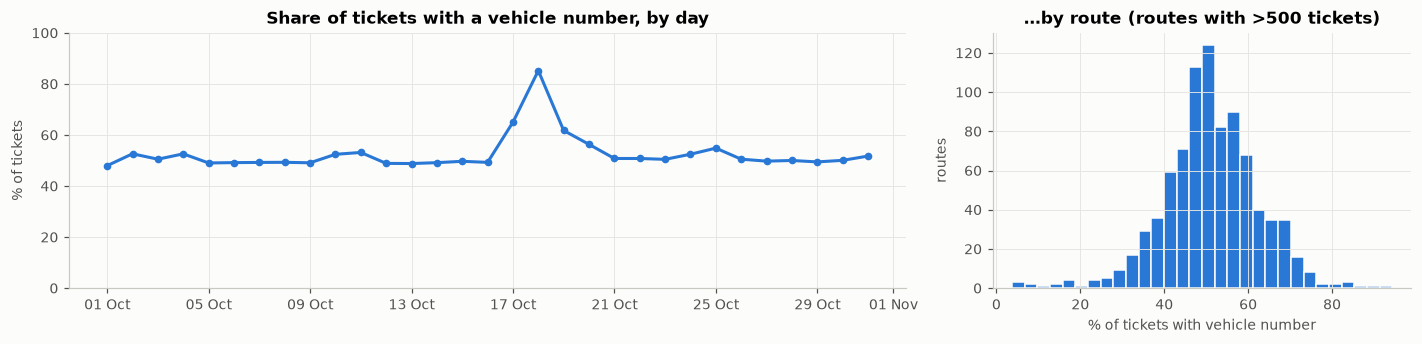

by is_ac:
is_ac
False   0.57
True    0.50
Name: share with vehicle_number, dtype: float64


In [6]:
veh_daily = df.groupby('date')['vehicle_number'].apply(lambda s: s.notna().mean())
veh_route = df.groupby('route')['vehicle_number'].agg(lambda s: s.notna().mean())[df.route.value_counts() > 500]

fig, axes = plt.subplots(1, 2, figsize=(13, 3.2), gridspec_kw={'width_ratios': [2, 1]})
ax = axes[0]
ax.plot(veh_daily.index, veh_daily.values * 100, color=BLUE, marker='o', ms=4)
ax.set_title('Share of tickets with a vehicle number, by day')
ax.set_ylabel('% of tickets'); ax.set_ylim(0, 100)
ax.xaxis.set_major_formatter(mdates.DateFormatter('%d %b'))
ax = axes[1]
ax.hist(veh_route.values * 100, bins=30, color=BLUE, edgecolor='#fcfcfb', linewidth=1)
ax.set_title('…by route (routes with >500 tickets)')
ax.set_xlabel('% of tickets with vehicle number'); ax.set_ylabel('routes')
plt.tight_layout(); plt.show()
print(f"by is_ac:\n{df.groupby('is_ac')['vehicle_number'].apply(lambda s: s.notna().mean()).rename('share with vehicle_number')}")

**Stop names are free text and not consistent.** The same place appears under several spellings, so names must be cleaned and
matched to GTFS stop IDs before any map or stop-sequence work. A few examples:

In [7]:
all_stops = pd.concat([df.start_stop_name, df.end_stop_name]).value_counts()
for pat in ['Saket Metro', 'Mahipal Pur', 'Badarpur', 'Kashmere Gate|Kashmiri Gate|ISBT']:
    hits = all_stops[all_stops.index.str.contains(pat, case=False, regex=True)].head(8)
    print(f'— "{pat}" —'); print(hits.to_string()); print()

— "Saket Metro" —
Saket Metro Sation / Said-Ul-Ajaib    18029
Saket Metro Station                   16718
Saket Metro Sation                     1601
Saidul-A-Jab / Saket Metro Station     1376
Saidulajab / Saket Metro Station       1323

— "Mahipal Pur" —
Mahipal Pur                                            23401
Mahipal Pur Village                                    19561
Mahipal Pur (Nh8)                                      16981
Mahipal Pur Village / Sec E Pkt 2 Vasant Kunj          10262
Mahipal Pur Village / Mahipal Pur Crossing Nh8          6569
Mahipal Pur Crossing                                    5193
Reddison Hotel Mahipal Pur / Rang Puri (Nh8 Circle)     3883
Mahipal Pur Extension                                   1295

— "Badarpur" —
Badarpur Border (T)                         39727
Badarpur Border                             20533
Badarpur Border(T)                          12952
Badarpur                                    10461
Pul Prehladpur ( Badarpur)             

## 4 · Fares decode the distance band

Every fare is **90 % of a standard DTC slab fare** — the 10 % discount given on digital (app/QR) tickets:
AC slabs ₹10/15/20/25 → ₹9 / 13.5 / 18 / 22.5; non-AC slabs ₹5/10/15 → ₹4.5 / 9 / 13.5.
Two consequences:

1. **This file is the digital e-ticket stream, not conductor ETM paper tickets** (those would show full ₹5/10/15/20/25 fares — they are absent).
2. **The fare slab is a free proxy for trip length**, useful to sanity-check the planned alighting stop and an inferred stop order.

In [8]:
fare_tab = (df.assign(fare=df.fare_per_pax.round(2))
              .groupby(['is_ac', 'fare']).size().rename('tickets').reset_index())
fare_tab['share_within_bus_type_%'] = fare_tab.groupby('is_ac')['tickets'].transform(lambda s: s / s.sum() * 100)
fare_tab['implied_full_fare_₹'] = (fare_tab['fare'] / 0.9).round(2)
fare_tab.sort_values(['is_ac', 'tickets'], ascending=[True, False]).groupby('is_ac').head(6).reset_index(drop=True)

,is_ac,fare,tickets,share_within_bus_type_%,implied_full_fare_₹
0,False,4.50,189711,37.88,5.00
1,False,9.00,188353,37.61,10.00
2,False,13.50,122741,24.51,15.00
3,False,0.00,1,0.00,0.00
4,False,22.50,1,0.00,25.00
5,True,9.00,838086,40.70,10.00
6,True,13.50,690561,33.54,15.00
7,True,18.00,274722,13.34,20.00
8,True,22.50,237865,11.55,25.00
9,True,26.50,6441,0.31,29.44


In [9]:
standard = {(True, 9.0): 'AC ₹10', (True, 13.5): 'AC ₹15', (True, 18.0): 'AC ₹20', (True, 22.5): 'AC ₹25',
            (False, 4.5): 'Non-AC ₹5', (False, 9.0): 'Non-AC ₹10', (False, 13.5): 'Non-AC ₹15'}
slab = pd.Series([standard.get(k) for k in zip(df.is_ac, df.fare_per_pax.round(2))], index=df.index)
df['fare_slab'] = slab
print(f"Tickets matching a standard discounted slab: {slab.notna().mean():.2%}")
print(f"Tickets at full (undiscounted) fares 5/10/15/20/25: {df.fare_per_pax.isin([5,10,15,20,25]).mean():.3%}")

Tickets matching a standard discounted slab: 99.30%


Tickets at full (undiscounted) fares 5/10/15/20/25: 0.000%


## 5 · When people travel

Ticket purchase time ≈ boarding time, so these are **boardings**. October 2026 contains two holidays visible in the data:
**Gandhi Jayanti (Fri 2 Oct)** and **Dussehra (Tue 20 Oct)**. They are excluded from the "typical day" profiles below.

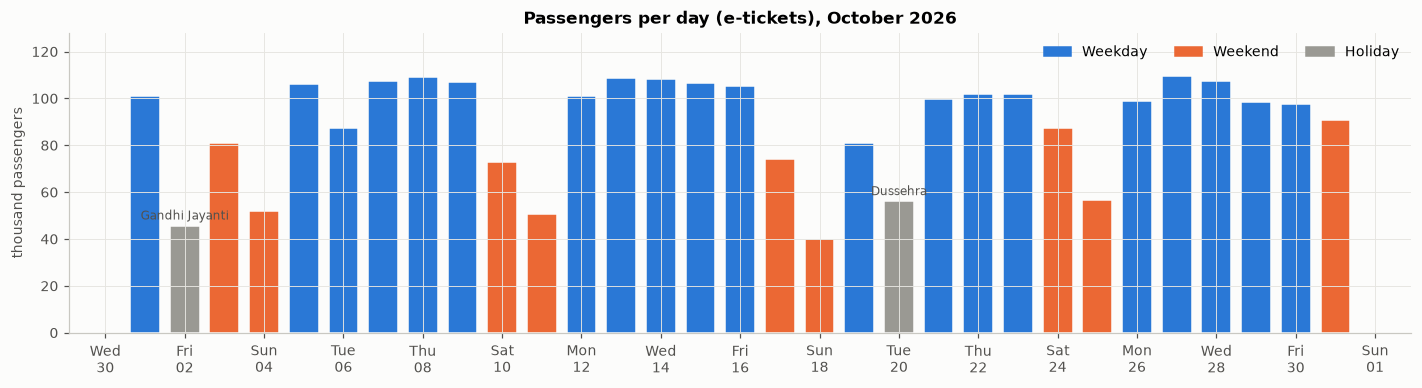

,days,mean,min,max
day_type,,,,
Holiday,2,"50,904.00",45706,56102
Saturday,5,"81,251.00",72796,90818
Sunday,4,"49,872.50",40103,56767
Weekday,20,"102,302.65",80945,109569


In [10]:
HOLIDAYS = {pd.Timestamp('2026-10-02'): 'Gandhi Jayanti', pd.Timestamp('2026-10-20'): 'Dussehra'}
df['day_type'] = np.select([df.date.isin(list(HOLIDAYS)), df.dow == 6, df.dow == 5],
                           ['Holiday', 'Sunday', 'Saturday'], 'Weekday')

daily = df.groupby('date').agg(pax=('passenger_count', 'sum'), tickets=('route', 'size'),
                               day_type=('day_type', 'first'))
colors = daily.day_type.map({'Weekday': BLUE, 'Saturday': ORANGE, 'Sunday': ORANGE, 'Holiday': GREY})

fig, ax = plt.subplots(figsize=(13, 3.6))
ax.bar(daily.index, daily.pax / 1e3, color=colors.tolist(), width=0.75, edgecolor='#fcfcfb', linewidth=1)
for d, name in HOLIDAYS.items():
    ax.annotate(name, (d, daily.loc[d, 'pax'] / 1e3), xytext=(0, 4), textcoords='offset points',
                ha='center', fontsize=8, color='#52514e')
ax.set_title('Passengers per day (e-tickets), October 2026')
ax.set_ylabel('thousand passengers'); ax.set_ylim(0, 128)
ax.xaxis.set_major_locator(mdates.DayLocator(interval=2)); ax.xaxis.set_major_formatter(mdates.DateFormatter('%a\n%d'))
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color=BLUE, label='Weekday'), Patch(color=ORANGE, label='Weekend'), Patch(color=GREY, label='Holiday')],
          loc='upper right', ncol=3)
plt.tight_layout(); plt.show()
daily.groupby('day_type')['pax'].agg(['count', 'mean', 'min', 'max']).rename(columns={'count': 'days'})

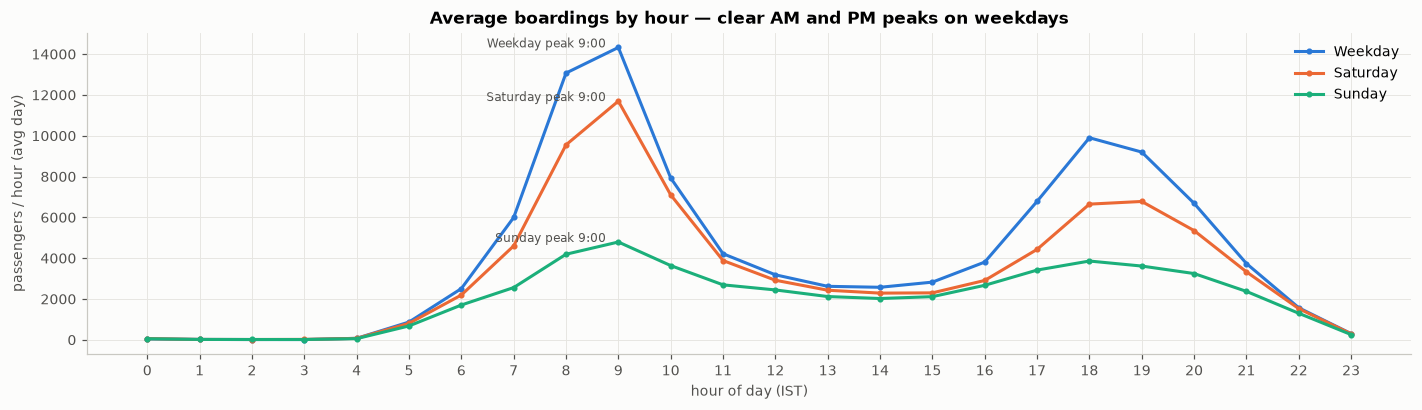

Weekday AM peak 08–10h: 27% of the day's boardings | PM peak 17–20h: 25% | 05–23h holds 99.5%


In [11]:
n_days = df.groupby('day_type')['date'].nunique()
hourly = (df.groupby(['day_type', 'hour'])['passenger_count'].sum().unstack(0)
            .reindex(range(24)).fillna(0) / n_days)

fig, ax = plt.subplots(figsize=(13, 3.8))
for dt, c in [('Weekday', BLUE), ('Saturday', ORANGE), ('Sunday', AQUA)]:
    ax.plot(hourly.index, hourly[dt], color=c, label=dt, marker='o', ms=3)
    pk = hourly[dt].idxmax()
    ax.annotate(f'{dt} peak {pk}:00', (pk, hourly.loc[pk, dt]), xytext=(-8, 0), ha='right', textcoords='offset points', fontsize=8, color='#52514e')
ax.set_xticks(range(24)); ax.set_xlabel('hour of day (IST)'); ax.set_ylabel('passengers / hour (avg day)')
ax.set_title('Average boardings by hour — clear AM and PM peaks on weekdays')
ax.legend(loc='upper right'); plt.tight_layout(); plt.show()

wk = hourly['Weekday']
print(f"Weekday AM peak 08–10h: {wk.loc[8:9].sum()/wk.sum():.0%} of the day's boardings | "
      f"PM peak 17–20h: {wk.loc[17:19].sum()/wk.sum():.0%} | 05–23h holds {wk.loc[5:22].sum()/wk.sum():.1%}")

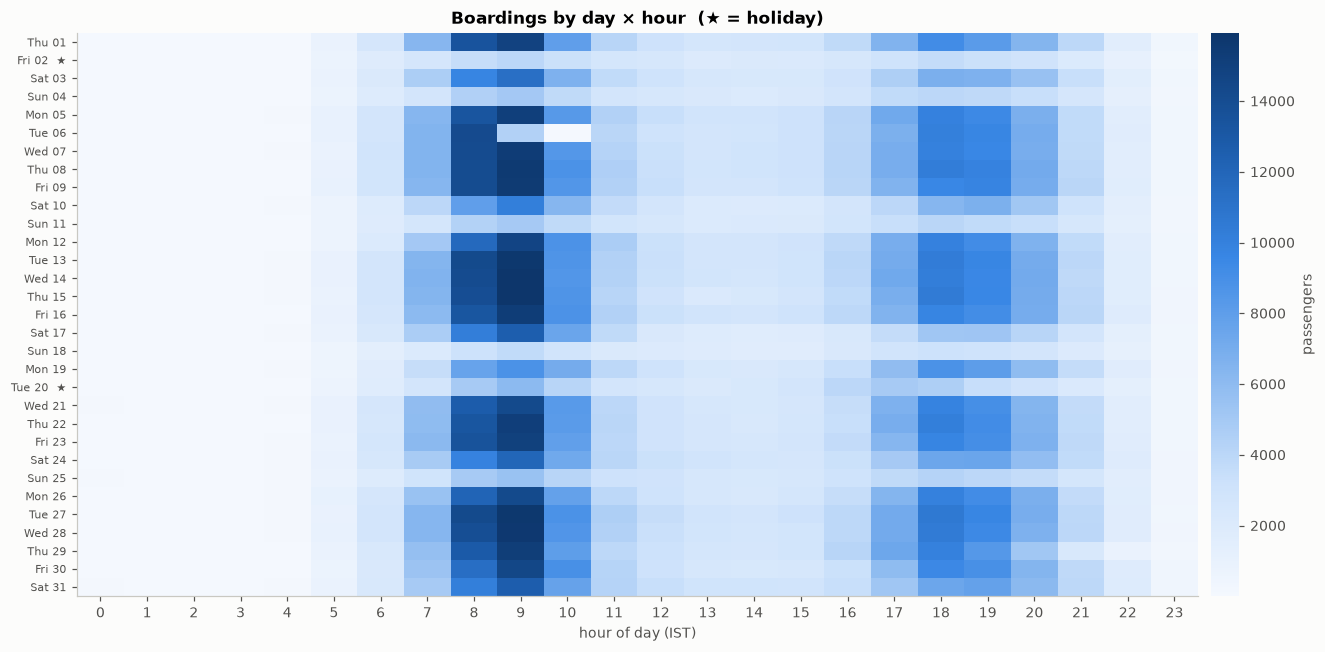

In [12]:
heat = df.groupby(['date', 'hour'])['passenger_count'].sum().unstack().reindex(columns=range(24)).fillna(0)
fig, ax = plt.subplots(figsize=(13, 6))
im = ax.imshow(heat.values, aspect='auto', cmap=SEQ, interpolation='nearest')
ax.set_yticks(range(len(heat))); ax.set_yticklabels([f"{d:%a %d}" + ('  ★' if d in HOLIDAYS else '') for d in heat.index], fontsize=7)
ax.set_xticks(range(24)); ax.set_xlabel('hour of day (IST)'); ax.grid(False)
ax.set_title('Boardings by day × hour  (★ = holiday)')
cb = plt.colorbar(im, ax=ax, pad=0.01); cb.set_label('passengers'); cb.outline.set_visible(False)
plt.tight_layout(); plt.show()

### Is the pattern stable week to week?

The brief asks teams to check that estimates hold from one week to the next. Here the unit is **route-direction × hour on
weekdays** — the grain a crowding model will work at. Each week is compared with every other.

In [13]:
wd = df[df.day_type == 'Weekday'].copy()
wd['week'] = wd.created_at.dt.isocalendar().week.astype(int)
full_weeks = wd.groupby('week')['date'].nunique()
full_weeks = full_weeks[full_weeks >= 4].index           # weeks with at least 4 normal weekdays
top_routes = df.route.value_counts().head(300).index
cell = (wd[wd.route.isin(top_routes) & wd.week.isin(full_weeks)]
        .groupby(['week', 'route', 'hour'])['passenger_count'].sum()
        .div(wd.groupby('week')['date'].nunique(), level='week')       # per-weekday average
        .unstack('week').fillna(0))
print('weeks used (ISO week: weekdays):', full_weeks.tolist(), '| cells (route-dir × hour):', len(cell))
corr = cell.corr().round(3)
corr.index = corr.columns = [f'wk {w}' for w in corr.columns]
corr

weeks used (ISO week: weekdays): [41, 42, 43, 44] | cells (route-dir × hour): 5710


,wk 41,wk 42,wk 43,wk 44
wk 41,1.00,0.96,0.95,0.95
wk 42,0.96,1.00,0.96,0.97
wk 43,0.95,0.96,1.00,0.97
wk 44,0.95,0.97,0.97,1.00


## 6 · Network coverage — how much data per route and hour?

A crowding estimate is only as good as the number of tickets behind it. This section shows where the data is thick and where it is thin.

2,259 route-directions | 1,249 base routes
passengers per route-direction for the month, quantiles: {0.1: 4, 0.25: 39, 0.5: 272, 0.75: 1215, 0.9: 3242}
  top 10% of route-directions carry 59% of passengers
  top 25% of route-directions carry 84% of passengers
  top 50% of route-directions carry 97% of passengers


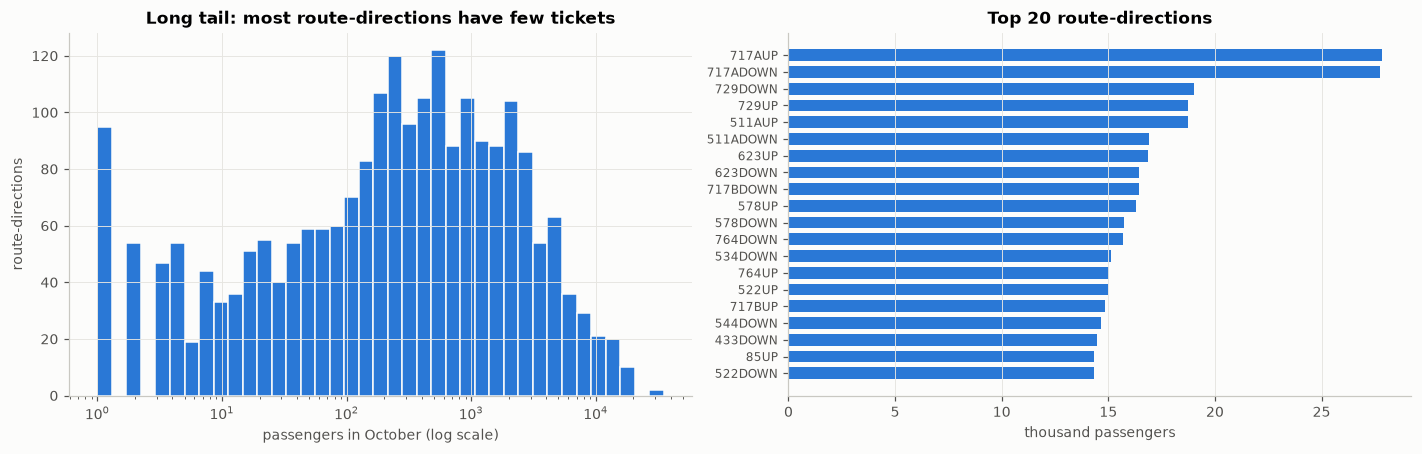

In [14]:
per_route = df.groupby('route')['passenger_count'].sum().sort_values(ascending=False)
q = per_route.quantile([.1, .25, .5, .75, .9]).astype(int)
print(f"{len(per_route):,} route-directions | {df.route_base.nunique():,} base routes")
print('passengers per route-direction for the month, quantiles:', q.to_dict())
cum = per_route.cumsum() / per_route.sum()
for k in [0.10, 0.25, 0.50]:
    print(f"  top {k:.0%} of route-directions carry {cum.iloc[int(len(cum)*k)-1]:.0%} of passengers")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
ax = axes[0]
bins = np.logspace(0, np.log10(per_route.max()) + 0.1, 40)
ax.hist(per_route.values, bins=bins, color=BLUE, edgecolor='#fcfcfb', linewidth=1)
ax.set_xscale('log'); ax.set_xlabel('passengers in October (log scale)'); ax.set_ylabel('route-directions')
ax.set_title('Long tail: most route-directions have few tickets')
ax = axes[1]
top20 = per_route.head(20)[::-1]
ax.barh(top20.index, top20.values / 1e3, color=BLUE, height=0.7)
ax.set_xlabel('thousand passengers'); ax.set_title('Top 20 route-directions'); ax.tick_params(axis='y', labelsize=8)
ax.grid(axis='y', visible=False)
plt.tight_layout(); plt.show()

In [15]:
# How many (route-direction × hour) cells have enough weekday data to estimate on their own?
svc = wd[wd.hour.between(6, 22)]
cnt = svc.groupby(['route', 'hour'])['passenger_count'].sum()
n_wd = wd['date'].nunique()
rows = []
for thr in [1, 20, 50, 100, 200]:
    ok = cnt >= thr
    rows.append({'min passengers in cell (month, weekdays)': thr, 'cells meeting it': f"{ok.mean():.0%}",
                 'passengers covered': f"{cnt[ok].sum()/cnt.sum():.0%}", '≈ per weekday': round(thr / n_wd, 1)})
print(f"{len(cnt):,} non-empty route-direction × hour cells (06–22h, {n_wd} normal weekdays)")
pd.DataFrame(rows)

26,470 non-empty route-direction × hour cells (06–22h, 20 normal weekdays)


,"min passengers in cell (month, weekdays)",cells meeting it,passengers covered,≈ per weekday
0,1,100%,100%,0.10
1,20,50%,96%,1.00
2,50,32%,88%,2.50
3,100,20%,77%,5.00
4,200,10%,59%,10.00


## 7 · Stops and origin–destination pairs

In [16]:
stops_per_route = df.groupby('route')['start_stop_name'].nunique()
print(f"distinct boarding stops per route-direction: median {stops_per_route.median():.0f}, "
      f"90th pct {stops_per_route.quantile(.9):.0f}")

peak = lambda lo, hi: df[(df.day_type == 'Weekday') & df.hour.between(lo, hi)]
top_board = pd.DataFrame({
    'all day': df.groupby('start_stop_name')['passenger_count'].sum().nlargest(12).index,
    'AM peak 07–10h (boarding)': peak(7, 9).groupby('start_stop_name')['passenger_count'].sum().nlargest(12).index,
    'PM peak 17–20h (boarding)': peak(17, 19).groupby('start_stop_name')['passenger_count'].sum().nlargest(12).index,
    'AM peak 07–10h (alighting)': peak(7, 9).groupby('end_stop_name')['passenger_count'].sum().nlargest(12).index,
})
top_board.index = range(1, 13)
top_board

distinct boarding stops per route-direction: median 25, 90th pct 52


,all day,AM peak 07–10h (boarding),PM peak 17–20h (boarding),AM peak 07–10h (alighting)
1,Hamdard Nagar / Sangam Vihar,Hamdard Nagar / Sangam Vihar,Saket Metro Station,Badarpur Border (T)
2,Saket Metro Station,Mehrauli Terminal,Said Ul Zeb Village,Saket Metro Sation / Said-Ul-Ajaib
3,Said Ul Zeb Village,Ambedkar Nagar Depot,Wazirpur Depot,Kapashera Border
4,Badarpur Border(T),Badarpur Border(T),Kapashera Border,Mori Gate Terminal
5,Mahipal Pur Village,Badarpur Border,Mahipal Pur Village,Said Ul Zeb Village
6,Mehrauli Terminal,Pul Prehladpur ( Badarpur),Andrews Ganj,Krishi Bhawan
7,Kapashera Border,Mother Dairy,Mahipal Pur,Nehru Place Terminal
8,Mahipal Pur,Mahipal Pur,Rithala Metro Station,Aiims
9,Dhaula Kuan,Kapashera Border,Krishi Bhawan,Wazirpur Depot
10,Ambedkar Nagar Depot,Mahipal Pur Village,Badarpur Border(T),Karol Bagh Metro Station


In [17]:
od = (df.groupby(['start_stop_name', 'end_stop_name', 'route'])['passenger_count'].sum()
        .nlargest(15).rename('passengers').reset_index())
od

,start_stop_name,end_stop_name,route,passengers
0,Mahipal Pur,Igi Airport Terminal-2,D-1103UP,1758
1,Palam Airport / Igi Airport T1,Igi Airport Terminal 3,AIRPORT-STLDOWN,1670
2,Badarpur Border,Noida Sector 37,8UP,1384
3,West Patel Nagar,Karol Bagh Metro Station,85DOWN,1367
4,Igi Airport Terminal 3,Palam Airport / Igi Airport T1,AIRPORT-STLUP,1330
5,Samalkha Village,Mahipal Pur (Nh8),729DOWN,1138
6,Badarpur Border (T),Kapashera Border,717AUP,1127
7,Reddison Hotel Mahipal Pur / Rang Puri (Nh8 Circle),Igi Airport Terminal 2 (Air India Office),D-034UP,1124
8,Kapashera Border,Mahipal Pur Village,717ADOWN,1113
9,Qutab Hotel,Panchsheel Club / Sarvpriya Vihar,511ADOWN,1108


## 8 · Buses and fleet

`vehicle_number` lets us tie tickets to a physical bus, and the registration series hints at the bus type
(e-bus vs CNG, AC vs non-AC) — which matters because "a load of 60 means different things on a 12 m and a 9 m bus".
The mapping from series to bus length/capacity is **not in the data** and has to come from DTC/DIMTS fleet lists.

In [18]:
fleet = (df.dropna(subset=['vehicle_number']).groupby('veh_prefix')
           .agg(tickets=('route', 'size'), buses=('vehicle_number', 'nunique'), ac_share=('is_ac', 'mean'),
                routes=('route_base', 'nunique'))
           .sort_values('tickets', ascending=False))
fleet['tickets_per_bus'] = (fleet.tickets / fleet.buses).round(0)
fleet.head(12)

,tickets,buses,ac_share,routes,tickets_per_bus
veh_prefix,,,,,
DL51EV,275794,1214,1.00,577,227.00
DL1PD4,203287,760,0.00,432,267.00
DL1PD5,183650,898,0.55,559,205.00
DL1PD8,174135,853,1.00,536,204.00
DL1PD7,137941,806,1.00,552,171.00
DL51GD,122975,693,1.00,542,177.00
DL1PD9,118314,910,1.00,494,130.00
DL1PD6,84131,435,1.00,478,193.00
DL1PE0,17505,240,1.00,225,73.00


In [19]:
bd = df.dropna(subset=['vehicle_number']).groupby(['vehicle_number', 'date']).agg(
    tickets=('route', 'size'), pax=('passenger_count', 'sum'), routes=('route', 'nunique'))
days_per_bus = df.dropna(subset=['vehicle_number']).groupby('vehicle_number')['date'].nunique()
pd.DataFrame({
    'e-ticket passengers per bus-day': bd.pax.describe(percentiles=[.25, .5, .75, .9]),
    'route-directions per bus-day': bd.routes.describe(percentiles=[.25, .5, .75, .9]),
    'active days per bus (of 31)': days_per_bus.describe(percentiles=[.25, .5, .75, .9]),
}).T.round(1)

,count,mean,std,min,25%,50%,75%,90%,max
e-ticket passengers per bus-day,"181,620.00",7.80,7.10,1.00,3.00,6.00,10.00,16.00,89.00
route-directions per bus-day,"181,620.00",2.60,1.20,1.00,2.00,2.00,3.00,4.00,11.00
active days per bus (of 31),"6,809.00",26.70,6.10,1.00,26.00,29.00,30.00,31.00,31.00


## 9 · How big a sample is this? (trip reconstruction test)

The brief's suggested method: *group tickets by bus trip and keep a running count*. To test this, tickets with a vehicle number
are chained into trips: same bus, same route-direction, and no gap longer than 30 minutes between consecutive tickets.

724,140 reconstructed bus trips from 1,317,732 tickets with a vehicle number


,1,2,3,4,5,6,7,8,9,10+
trips,421163,148317,68016,34751,19060,11491,6946,4512,3054,6830
share,58%,20%,9%,5%,3%,2%,1%,1%,0%,1%


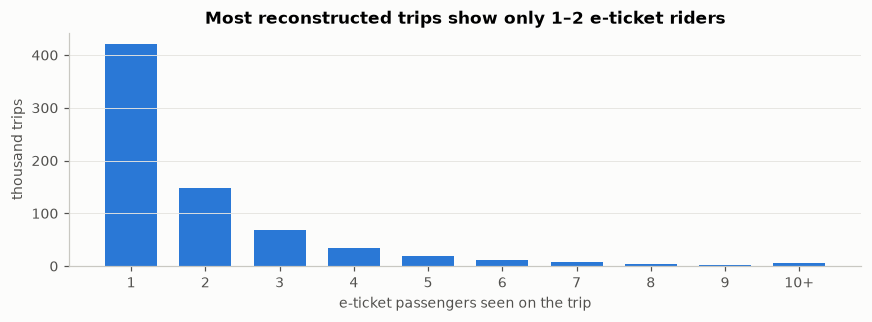

In [20]:
tv = df.dropna(subset=['vehicle_number']).sort_values(['vehicle_number', 'created_at'])[
    ['vehicle_number', 'route', 'created_at', 'passenger_count']].copy()
new_trip = ((tv.vehicle_number != tv.vehicle_number.shift()) | (tv.route != tv.route.shift()) |
            (tv.created_at.diff() > pd.Timedelta(minutes=30)))
tv['trip_id'] = new_trip.cumsum()
trips = tv.groupby('trip_id').agg(pax=('passenger_count', 'sum'), tickets=('route', 'size'),
                                  t0=('created_at', 'min'), t1=('created_at', 'max'))
trips['span_min'] = (trips.t1 - trips.t0).dt.total_seconds() / 60
print(f"{len(trips):,} reconstructed bus trips from {len(tv):,} tickets with a vehicle number")
dist = trips.pax.clip(upper=10).value_counts().sort_index()
dist.index = [str(i) if i < 10 else '10+' for i in dist.index]
display(pd.DataFrame({'trips': dist, 'share': (dist / dist.sum()).map('{:.0%}'.format)}).T)

fig, ax = plt.subplots(figsize=(8, 3))
ax.bar(dist.index, dist.values / 1e3, color=BLUE, width=0.7)
ax.set_xlabel('e-ticket passengers seen on the trip'); ax.set_ylabel('thousand trips')
ax.set_title('Most reconstructed trips show only 1–2 e-ticket riders'); ax.grid(axis='x', visible=False)
plt.tight_layout(); plt.show()

**What this means.** A Delhi city bus carries hundreds of riders a day, yet the median bus-day here has only a handful of e-tickets
(and only ~half of tickets carry a vehicle number). So this file is a **sample of riders — roughly a few percent** — not a census.
Riders who never appear: cash/ETM paper-ticket buyers, pass holders, and women travelling free on the pink-ticket/Saheli scheme.
The sketch below makes the arithmetic explicit; the riders-per-bus figure is an **assumption to replace with an official number**.

In [21]:
share_with_veh = df.vehicle_number.notna().mean()
med_pax_bus_day = bd.pax.median() / share_with_veh          # all e-tickets on a typical bus-day
for riders_per_bus_day in [400, 600, 900]:                   # ASSUMPTION: total riders per bus per day
    print(f"if a bus carries {riders_per_bus_day} riders/day → e-tickets ≈ {med_pax_bus_day / riders_per_bus_day:.1%} of riders "
          f"(scale-up factor ≈ {riders_per_bus_day / med_pax_bus_day:.0f}×)")

if a bus carries 400 riders/day → e-tickets ≈ 2.9% of riders (scale-up factor ≈ 34×)
if a bus carries 600 riders/day → e-tickets ≈ 1.9% of riders (scale-up factor ≈ 51×)
if a bus carries 900 riders/day → e-tickets ≈ 1.3% of riders (scale-up factor ≈ 77×)


## 10 · Feasibility check: can the data alone give a crowding profile along a route?

The CSV has no stop sequence (that comes from GTFS, which we don't have yet). But every ticket says *"boarded at A, going to B"*,
which means A comes before B on that route-direction. Voting over thousands of tickets recovers the stop order.
With the order known, each passenger is counted as **on board for every stretch between A and B** — the brief's
running count, done in aggregate instead of per trip. This is a proof of concept on the busiest route, not the final model.

In [22]:
def infer_stop_order(t, min_count=30):
    # Order stops on one route-direction using pairwise 'boarded at a → going to b' votes (Copeland ranking).
    cnt = pd.concat([t.start_stop_name, t.end_stop_name]).value_counts()
    keep = cnt[cnt >= min_count].index
    t = t[t.start_stop_name.isin(keep) & t.end_stop_name.isin(keep) & (t.start_stop_name != t.end_stop_name)]
    m = pd.crosstab(t.start_stop_name, t.end_stop_name, values=t.passenger_count, aggfunc='sum')
    m = m.reindex(index=keep, columns=keep).fillna(0)
    wins = (m.values > m.values.T).sum(1) - (m.values < m.values.T).sum(1)
    order = pd.Series(wins, index=keep).sort_values(ascending=False).index.tolist()
    pos = {s: i for i, s in enumerate(order)}
    t = t.assign(i_on=t.start_stop_name.map(pos), i_off=t.end_stop_name.map(pos))
    return order, t

def load_profile(t, order, bands, n_days):
    # Average e-ticket passengers crossing each stretch (stop i → i+1), per day, for each time band.
    out = {}
    for name, (h0, h1) in bands.items():
        s = t[t.hour.between(h0, h1 - 1)]
        diff = np.zeros(len(order) + 1)
        np.add.at(diff, s.i_on.values, s.passenger_count.values)
        np.add.at(diff, s.i_off.values, -s.passenger_count.values)
        out[name] = np.cumsum(diff)[:len(order) - 1] / n_days
    return pd.DataFrame(out, index=[f'{a} → {b}' for a, b in zip(order[:-1], order[1:])])

BANDS = {'AM peak 07–10h': (7, 10), 'Midday 11–16h': (11, 16), 'PM peak 17–20h': (17, 20)}
DEMO = df.route_base.value_counts().index[0]
print('Demo route:', DEMO)
results = {}
for d in ['UP', 'DOWN']:
    t = wd[wd.route == f'{DEMO}{d}']
    order, tt = infer_stop_order(t)
    consistent = (tt.i_on < tt.i_off).mean()
    results[d] = (order, tt, load_profile(tt, order, BANDS, n_wd))
    print(f"{DEMO}{d}: {len(order)} stops kept | {len(tt):,} weekday tickets | "
          f"{consistent:.1%} of tickets agree with the inferred order (boarding stop before alighting stop)")

Demo route: 717A


717AUP: 51 stops kept | 18,257 weekday tickets | 96.7% of tickets agree with the inferred order (boarding stop before alighting stop)
717ADOWN: 46 stops kept | 18,310 weekday tickets | 94.1% of tickets agree with the inferred order (boarding stop before alighting stop)


In [23]:
# Independent check: higher fare slab should mean a longer ride along the inferred order
chk = []
for d, (order, tt, _) in results.items():
    tt = tt[tt.i_on < tt.i_off]
    chk.append(tt.assign(direction=d, stops_travelled=tt.i_off - tt.i_on)
                 .groupby(['direction', 'fare_slab'])['stops_travelled'].agg(['median', 'mean', 'size']))
pd.concat(chk).round(1)

median  mean  size
direction fare_slab                     
UP        AC ₹10        9.00  9.30  3447
          AC ₹15       14.00 13.10  3245
          AC ₹20       20.00 18.20  2027
          AC ₹25       42.00 38.10  2369
          Non-AC ₹10   14.00 13.80  2172
          Non-AC ₹15   37.00 32.90  2413
          Non-AC ₹5     8.00  8.40  1987
DOWN      AC ₹10        9.00  9.40  3867
          AC ₹15       11.00 10.70  3938
          AC ₹20       21.00 19.40  1471
          AC ₹25       42.00 37.40  2050
          Non-AC ₹10    9.00  9.90  2473
          Non-AC ₹15   39.00 35.70  1681
          Non-AC ₹5     8.00  7.90  1747

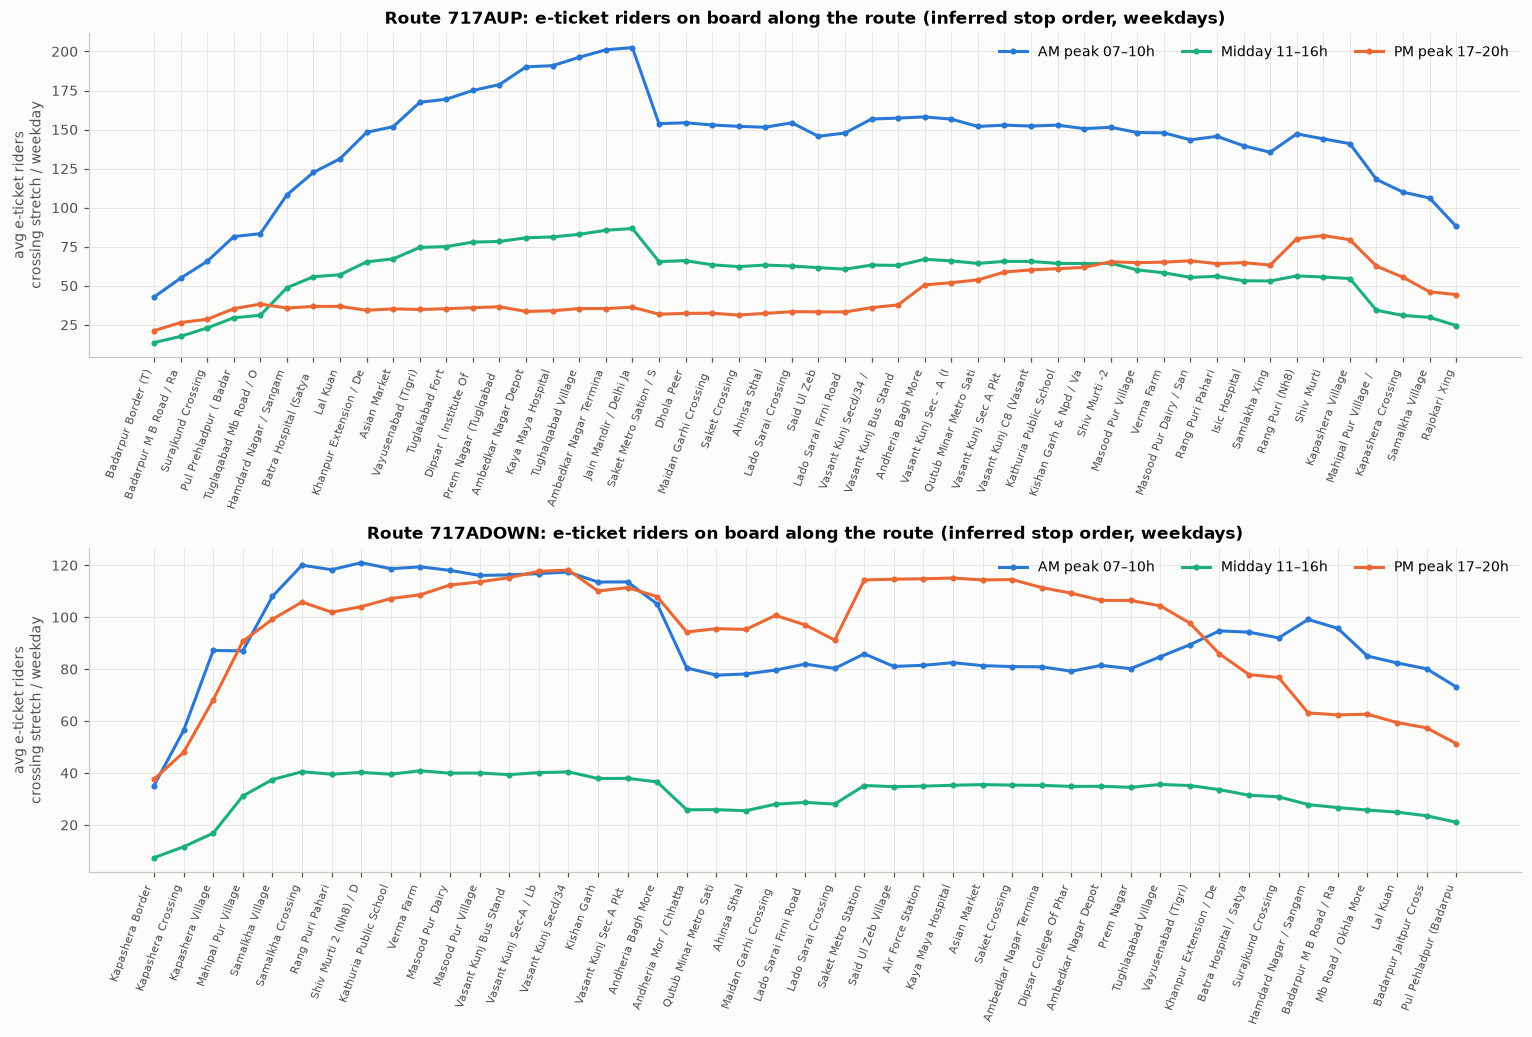

In [24]:
fig, axes = plt.subplots(2, 1, figsize=(14, 9.5))
for ax, (d, (order, tt, prof)) in zip(axes, results.items()):
    x = np.arange(len(prof))
    for (band, c) in zip(BANDS, [BLUE, AQUA, ORANGE]):
        ax.plot(x, prof[band].values, color=c, label=band, marker='o', ms=3)
    ax.set_xticks(x); ax.set_xticklabels([s.split(' → ')[0][:22] for s in prof.index], rotation=70, ha='right', fontsize=7)
    ax.set_ylabel('avg e-ticket riders\ncrossing stretch / weekday')
    ax.set_title(f'Route {DEMO}{d}: e-ticket riders on board along the route (inferred stop order, weekdays)')
    ax.legend(loc='upper right', ncol=3)
plt.tight_layout(); plt.show()

> Numbers above are **e-ticket riders only** and summed over all buses in the band. Turning them into "people on *a* bus" needs
> (a) the scale-up factor from §9, (b) buses per hour on that stretch (GTFS frequencies or the GPS feed), and (c) bus capacity by type (§8).

## 11 · Summary — what this data supports, and what it doesn't

**What's in it.** 2.56 M digital bus tickets (2.75 M passengers), every day of October 2026, 1,249 routes in both directions,
~7,100 stop names, 6,809 buses. Each record = route-direction, boarding stop, planned alighting stop, boarding time, fare, AC flag,
and (for 51 %) the bus registration.

**It is clean where it matters:** no missing times, routes or stops, no duplicates, 99.3 % of fares match a standard slab.
**It is messy where expected:** stop names are free text with several spellings per place, `ticket_type_id` is useless, half the
vehicle numbers are missing (randomly, except a spike on 17–19 Oct).

**The patterns are real and stable.** Weekday AM peak at 09:00 (larger) and PM peak at 18:00; Saturdays ~80 % of a weekday, Sundays
~50 %; holidays look like Sundays. Route × hour profiles correlate at ≥ 0.95 between every pair of weeks → a 4-week average is a
sound basis and the week-to-week check the brief asks for already passes at this grain.

**What can be built from it alone:**
- Stop order per route-direction, recovered from "boarded A → going to B" votes (94–97 % consistent; independently confirmed by
  fare slab rising with distance).
- A relative on-board load profile by route, direction, stretch and time band (the core of the crowding model) — §10 shows it working.
- Demand rankings: busiest corridors, stops and OD pairs by time of day; weekday vs weekend.
- A trip-length proxy from fare slab.

**What it cannot give on its own (gaps to fill):**
1. **Absolute crowding.** E-tickets are roughly 1–3 % of riders (cash/ETM paper tickets, passes and free pink-ticket riders are absent),
   and most reconstructed trips see only 1–2 e-ticket riders. Per-bus running counts from this file alone are not possible; loads must
   be aggregated and scaled. Needs an expansion factor (official route ridership, or ETM totals) or a calibrated relative index.
2. **Stop locations / sequences / schedules** → static GTFS (request on delhi.transportstack.in). Needed for the planner, the map, and
   to convert flows into per-bus loads via trips per hour.
3. **Bus capacity** → map registration series to bus type/length (12 m vs 9 m) from fleet lists.
4. **Thin routes** — half the route-direction × hour cells have < 1 rider/weekday; these need pooling (hour bands, neighbouring
   stretches, route-level priors) and an explicit confidence flag.
5. **Travel times** for the planner → GTFS schedule, or the October GPS feed (16 GB, optional) for observed times.

In [25]:
summary = {
    'tickets': f"{len(df):,}",
    'passengers': f"{int(df.passenger_count.sum()):,}",
    'days': df.date.nunique(),
    'route-directions / base routes': f"{df.route.nunique():,} / {df.route_base.nunique():,}",
    'distinct stop names (board/alight)': f"{df.start_stop_name.nunique():,} / {df.end_stop_name.nunique():,}",
    'buses seen': f"{df.vehicle_number.nunique():,}",
    'tickets with vehicle number': f"{df.vehicle_number.notna().mean():.0%}",
    'AC share of tickets': f"{df.is_ac.mean():.0%}",
    'avg weekday / Sat / Sun passengers': ' / '.join(f"{daily[daily.day_type==k].pax.mean():,.0f}" for k in ['Weekday', 'Saturday', 'Sunday']),
    'weekday AM peak hour / PM peak hour': f"{hourly['Weekday'].loc[:12].idxmax()}:00 / {hourly['Weekday'].loc[12:].idxmax()}:00",
    'week-to-week corr (route×hour, weekdays), min': f"{corr.where(~np.eye(len(corr), dtype=bool)).min().min():.3f}",
    'median e-ticket riders per reconstructed trip': f"{trips.pax.median():.0f}",
}
pd.Series(summary, name='value').to_frame()

,value
tickets,"2,559,899"
passengers,"2,753,606"
days,31
route-directions / base routes,"2,259 / 1,249"
distinct stop names (board/alight),"7,148 / 6,941"
buses seen,"6,809"
tickets with vehicle number,51%
AC share of tickets,80%
avg weekday / Sat / Sun passengers,"102,303 / 81,251 / 49,872"
weekday AM peak hour / PM peak hour,9:00 / 18:00
